# Contrast Stretching — Image Enhancement

 It compares the original and enhanced grayscale image and their intensity histograms.

> The original coursework used OpenCV, NumPy, and Matplotlib. This version keeps the same core method while improving input validation, handling constant-intensity images, and removing the hard-coded Google Colab file path.

## 1. Imports

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "gray"

## 2. Load a grayscale image

In Google Colab, you can upload an image when prompted. When running locally, set `IMAGE_PATH` to the path of your image.

Saving images.jpeg to images.jpeg
Image shape: (488, 628)
Data type: uint8


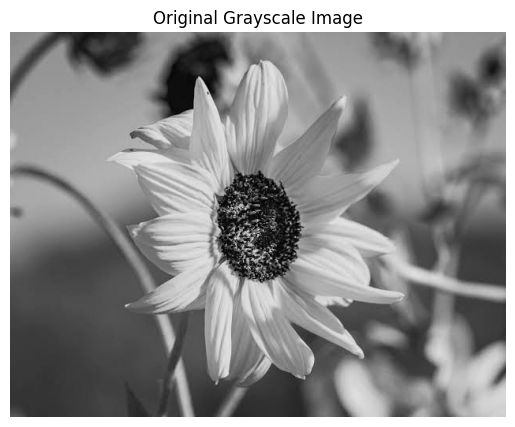

In [2]:
# Option A: Upload an image in Google Colab
try:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        image_path = next(iter(uploaded))
    else:
        raise ValueError("No image was uploaded.")
except ImportError:
    # Option B: Local execution
    IMAGE_PATH = "/content/images/images.jpeg"
    image_path = IMAGE_PATH

image_path = Path(image_path)
image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError(
        f"Could not read image: {image_path}. Check the path and file format."
    )

print(f"Image shape: {image.shape}")
print(f"Data type: {image.dtype}")
plt.imshow(image)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

## 3. Contrast stretching

Min–max contrast stretching maps the minimum intensity in the input image to 0 and the maximum intensity to 255:

\[ I_{out} = \frac{I_{in} - I_{min}}{I_{max} - I_{min}} \times 255 \]

A constant-intensity image (`I_min == I_max`) is handled separately to avoid division by zero.

In [3]:
def contrast_stretching(gray_image: np.ndarray) -> tuple[np.ndarray, int, int]:
    """Apply min-max contrast stretching to a grayscale image.

    Args:
        gray_image: 2D grayscale image.

    Returns:
        A tuple containing the stretched uint8 image, minimum input
        intensity, and maximum input intensity.
    """
    if gray_image is None or gray_image.size == 0:
        raise ValueError("Input image is empty.")
    if gray_image.ndim != 2:
        raise ValueError("Expected a 2D grayscale image.")

    image_float = gray_image.astype(np.float32)
    r_min = float(np.min(image_float))
    r_max = float(np.max(image_float))

    if r_max == r_min:
        # No contrast can be expanded when all pixels have the same value.
        stretched = np.zeros_like(gray_image, dtype=np.uint8)
    else:
        stretched = (image_float - r_min) * (255.0 / (r_max - r_min))
        stretched = np.clip(stretched, 0, 255).astype(np.uint8)

    return stretched, int(r_min), int(r_max)

stretched, rmin, rmax = contrast_stretching(image)
print(f"Minimum intensity: {rmin}")
print(f"Maximum intensity: {rmax}")

Minimum intensity: 0
Maximum intensity: 236


## 4. Visual comparison

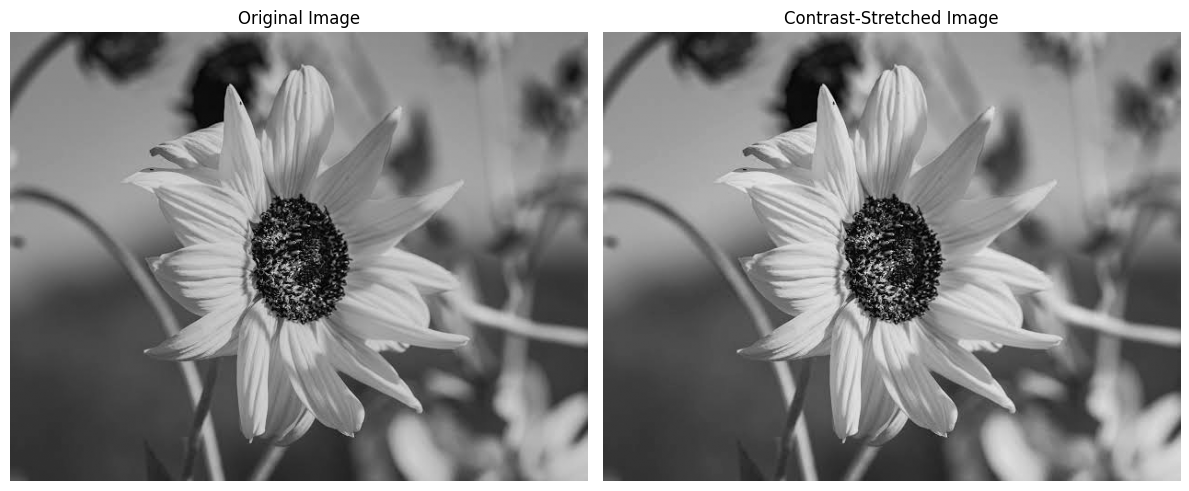

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image, vmin=0, vmax=255)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(stretched, vmin=0, vmax=255)
axes[1].set_title("Contrast-Stretched Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 5. Histogram comparison

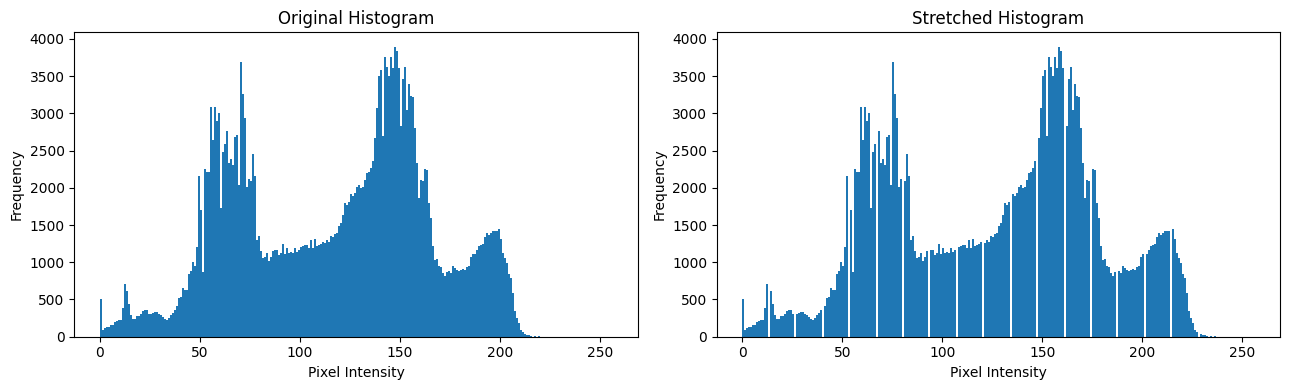

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(image.ravel(), bins=256, range=(0, 256))
axes[0].set_title("Original Histogram")
axes[0].set_xlabel("Pixel Intensity")
axes[0].set_ylabel("Frequency")

axes[1].hist(stretched.ravel(), bins=256, range=(0, 256))
axes[1].set_title("Stretched Histogram")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 6. Simple numerical comparison

The intensity range and standard deviation provide a compact description of the contrast change. They do not, by themselves, measure perceptual image quality.

In [6]:
def image_summary(gray_image: np.ndarray) -> dict:
    return {
        "Minimum intensity": int(np.min(gray_image)),
        "Maximum intensity": int(np.max(gray_image)),
        "Intensity range": int(np.max(gray_image) - np.min(gray_image)),
        "Standard deviation": float(np.std(gray_image)),
    }

comparison = {
    "Original": image_summary(image),
    "Contrast stretched": image_summary(stretched),
}

for label, metrics in comparison.items():
    print(f"\n{label}")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.3f}" if isinstance(value, float) else f"{metric}: {value}")


Original
Minimum intensity: 0
Maximum intensity: 236
Intensity range: 236
Standard deviation: 48.284

Contrast stretched
Minimum intensity: 0
Maximum intensity: 255
Intensity range: 255
Standard deviation: 52.174


## 7. Conclusion

Min–max contrast stretching expands the available grayscale intensity range to improve global contrast. The before/after images and histograms show how pixel intensities are redistributed. The method is simple and effective when the input image uses only a limited intensity range, but it can also amplify noise and does not adapt separately to local image regions.